¡Listo! Archivo 'visualizacion_areas_verdes.jpg' guardado con éxito.


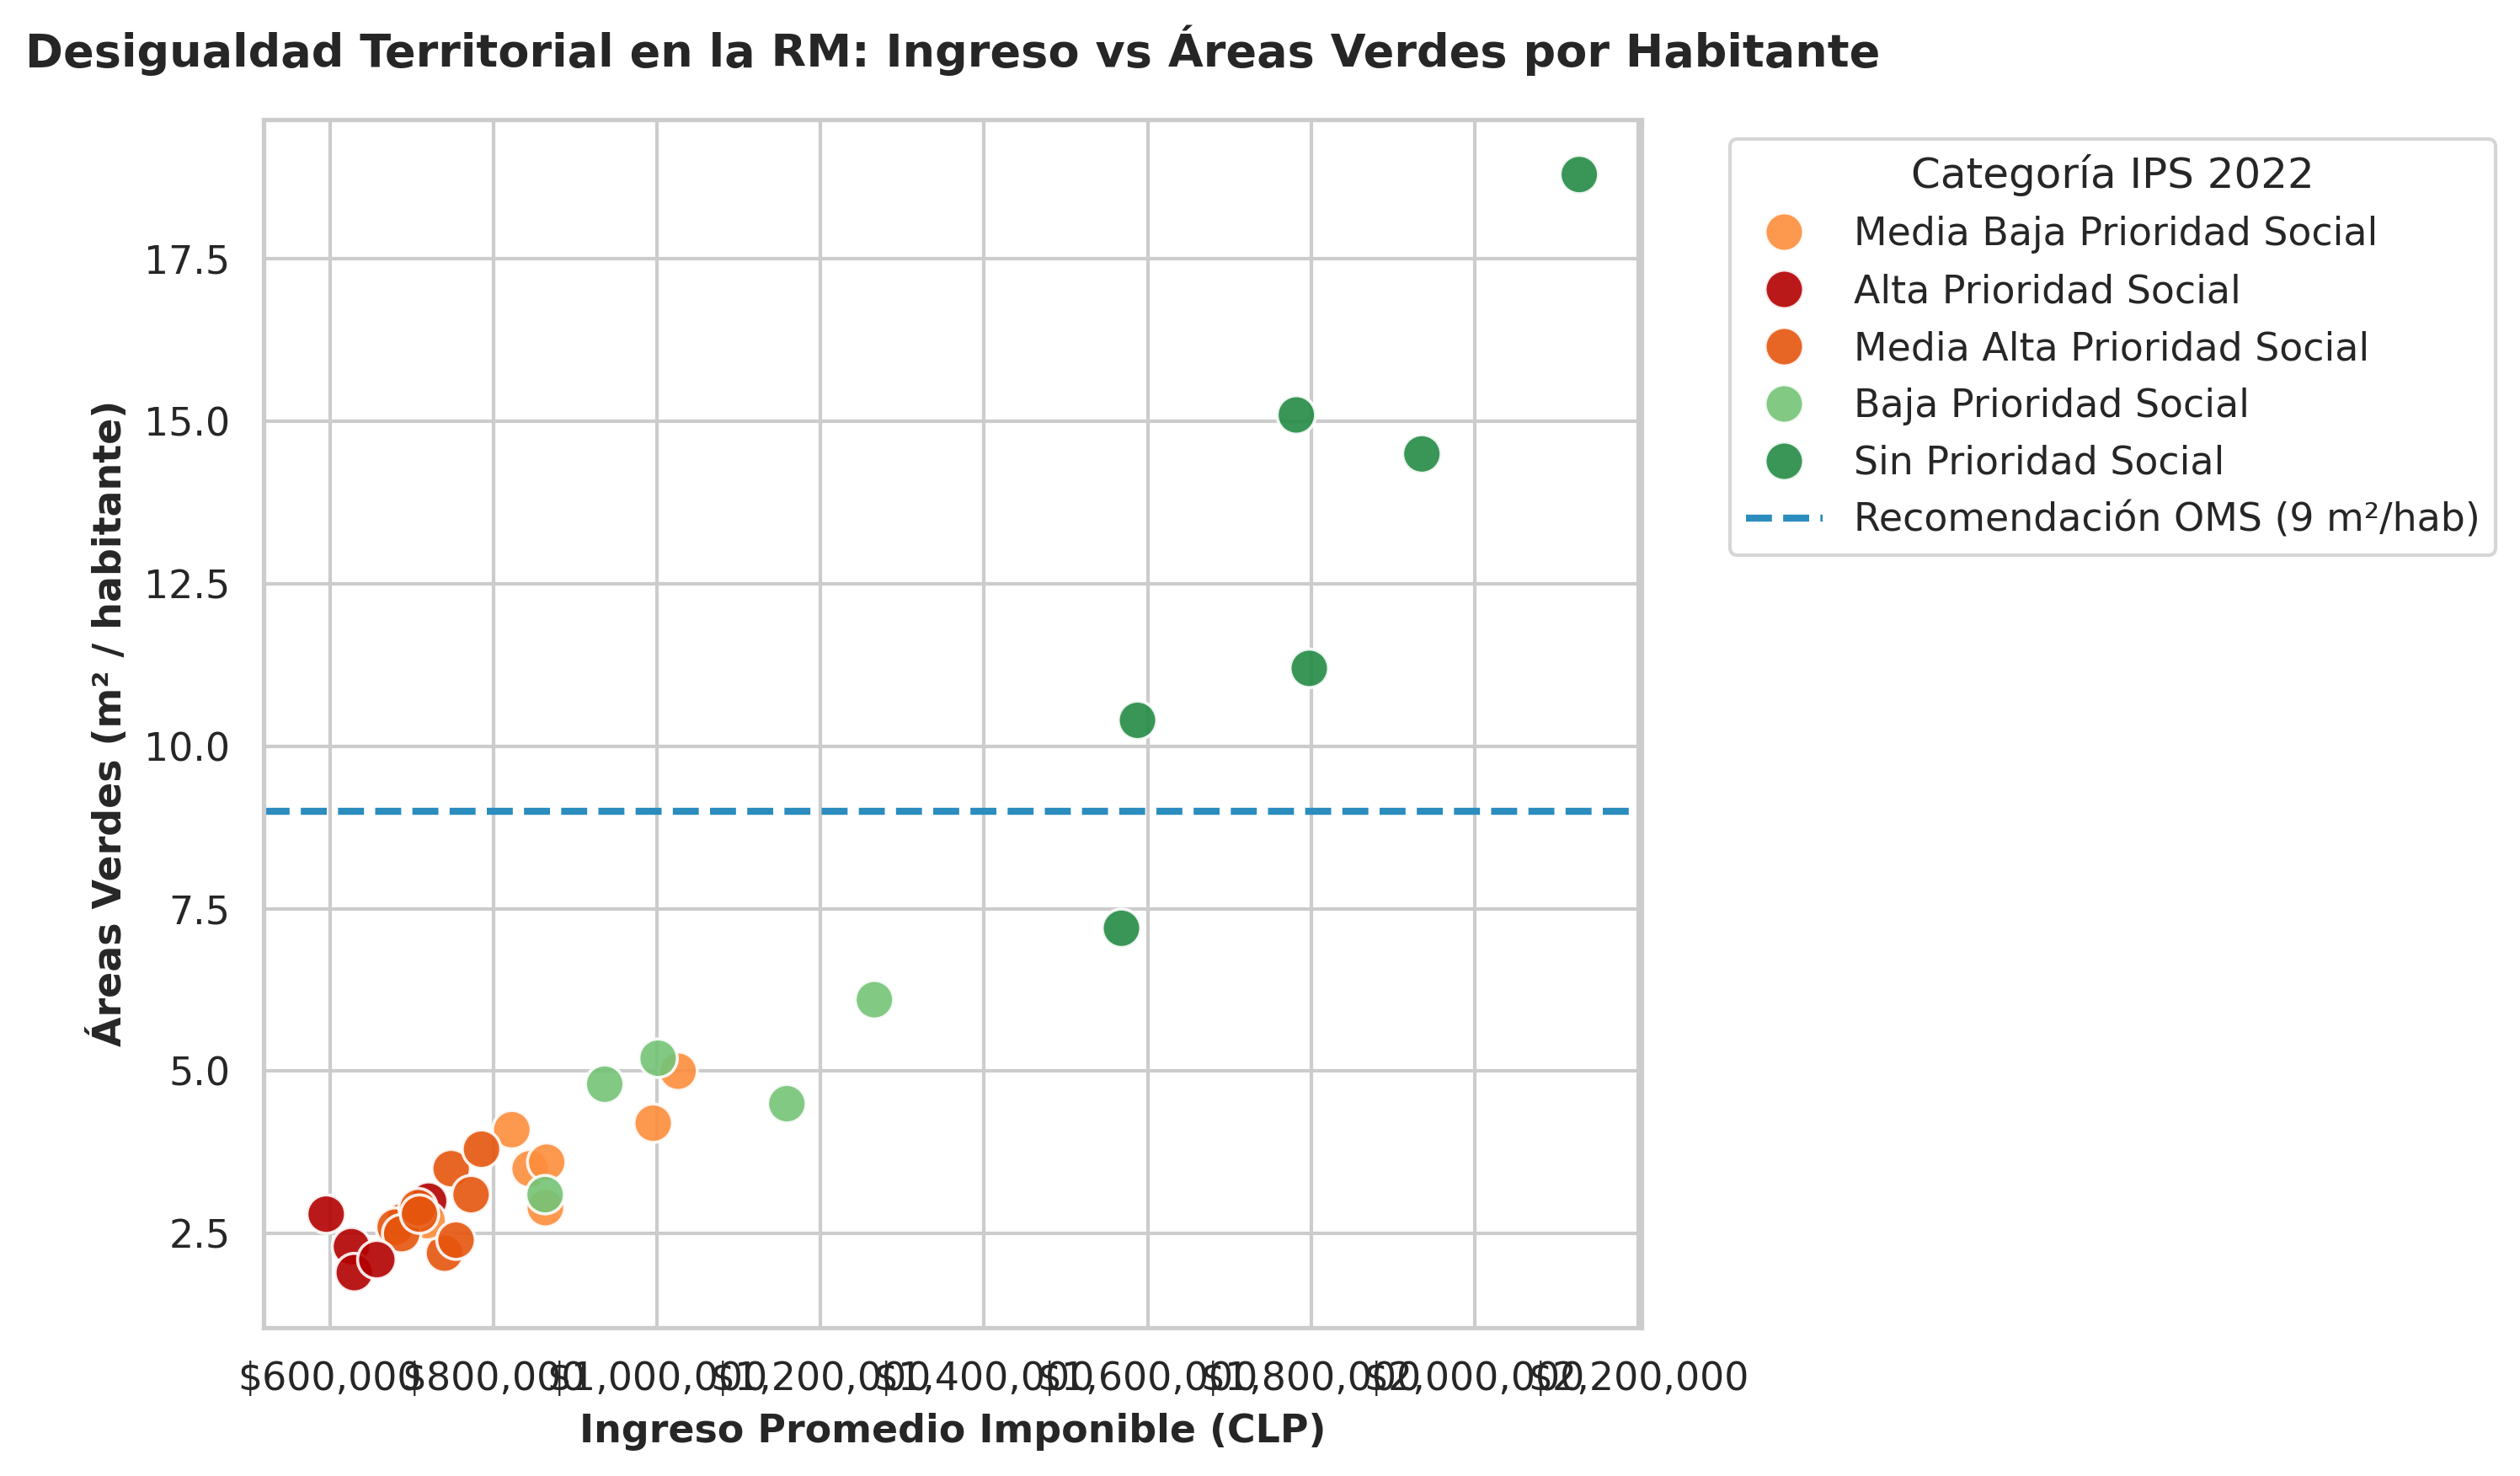

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Cargar datos
df = pd.read_csv('base de datos limpia.csv', sep=';')
pivoted = df.pivot(index=['Comuna', 'IPS_2022', 'Categoria_IPS_2022'],
                   columns='Indicador',
                   values='Valor').reset_index()
pivoted['Ingreso_Promedio'] = pivoted['Ingreso_imponible_AFC_2020'] / 10

green_spaces = {
    'Vitacura': 18.8, 'Las Condes': 14.5, 'Providencia': 11.2, 'Lo Barnechea': 15.1,
    'La Reina': 10.4, 'Ñuñoa': 7.2, 'Huechuraba': 6.1, 'Santiago': 5.2,
    'Peñalolén': 5.0, 'Maipú': 4.8, 'San Miguel': 4.5, 'La Florida': 4.2,
    'Cerrillos': 4.1, 'San Bernardo': 3.8, 'Puente Alto': 3.6, 'Recoleta': 3.5,
    'Pudahuel': 3.5, 'Quilicura': 3.1, 'San Joaquín': 3.1, 'Conchalí': 3.0,
    'La Cisterna': 2.9, 'Pedro Aguirre Cerda': 2.9, 'Renca': 2.8, 'La Pintana': 2.8,
    'El Bosque': 2.7, 'Independencia': 2.7, 'La Granja': 2.6, 'Lo Prado': 2.5,
    'Quinta Normal': 2.4, 'Cerro Navia': 2.3, 'Estación Central': 2.2,
    'San Ramón': 2.1, 'Lo Espejo': 1.9
}
pivoted['M2_Area_Verde_Hab'] = pivoted['Comuna'].map(green_spaces)
df_urban = pivoted.dropna(subset=['M2_Area_Verde_Hab']).copy()

# 2. Configurar gráfico con estilo limpio y profesional
plt.figure(figsize=(10, 6), dpi=300)
sns.set_theme(style="whitegrid")

palette = {
    'Alta Prioridad Social': '#b30000',
    'Media Alta Prioridad Social': '#e6550d',
    'Media Baja Prioridad Social': '#fd8d3c',
    'Baja Prioridad Social': '#74c476',
    'Sin Prioridad Social': '#238b45'
}

ax = sns.scatterplot(
    data=df_urban,
    x='Ingreso_Promedio',
    y='M2_Area_Verde_Hab',
    hue='Categoria_IPS_2022',
    palette=palette,
    s=120,
    alpha=0.9
)

# Línea de referencia OMS (9 m2/hab)
plt.axhline(9.0, color='#2b8cbe', linestyle='--', linewidth=2, label='Recomendación OMS (9 m²/hab)')

plt.title('Desigualdad Territorial en la RM: Ingreso vs Áreas Verdes por Habitante', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Ingreso Promedio Imponible (CLP)', fontsize=11, fontweight='bold')
plt.ylabel('Áreas Verdes (m² / habitante)', fontsize=11, fontweight='bold')

# Formato pesos chilenos en el eje X
ax.xaxis.set_major_formatter('${x:,.0f}')

plt.legend(title='Categoría IPS 2022', bbox_to_anchor=(1.05, 1), loc='upper left', frameon=True)
plt.tight_layout()

# Guardar en JPG
plt.savefig('visualizacion_areas_verdes.jpg', format='jpg', dpi=300)
print("¡Listo! Archivo 'visualizacion_areas_verdes.jpg' guardado con éxito.")